# Feature Engineering

**Goal:** create new features that bring business knowledge the model could not find on its own.

## 0. Setup

Imports and load the cleaned dataset.

`buildings_cleaned.parquet` is the output of the last section of `01_eda.ipynb`.

To generate it:

1. Make sure the raw file `data/raw/2016_Building_Energy_Benchmarking.csv` is present.
2. Run `notebooks/01_eda.ipynb` from top to bottom.
3. The file is written to `data/processed/buildings_cleaned.parquet`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

df = pd.read_parquet("../data/processed/buildings_cleaned.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

columns_to_drop = []

Dataset: 1535 rows x 13 columns


## 1. Parking share

A parking area has its own energy use (lighting, ventilation), which is counted in the total energy use of the property. The larger the parking relative to the building, the more it should weigh.

**Definition:** `ParkingShare = PropertyGFAParking / (PropertyGFABuilding(s) + PropertyGFAParking)`. It is 0 for properties without parking (a real value, not a missing one) and strictly below 1 as long as the building area is positive.

In [2]:
b = df["PropertyGFABuilding(s)"]
p = df["PropertyGFAParking"]

assert (b > 0).all(), "A property without building area would make the share equal to 1"
df["ParkingShare"] = p / (b + p)

has_parking = p > 0
print(
    f"Properties with a parking: {has_parking.sum()} / {len(df)} ({has_parking.mean():.1%})"
)
df.loc[has_parking, "ParkingShare"].describe()

Properties with a parking: 325 / 1535 (21.2%)


count    325.000000
mean       0.306185
std        0.150359
min        0.015281
25%        0.190961
50%        0.290781
75%        0.389316
max        0.798167
Name: ParkingShare, dtype: float64

### Presence or share of the parking?

79% of the properties have no parking, so the share has a large mass at 0. Two questions: how is the share distributed among properties with a parking, and which signal (has a parking or not / how large it is) relates best to energy use?

Energy use is strongly driven by building size, so it is divided by the building area (parking excluded) and log-transformed to compare buildings of different sizes.

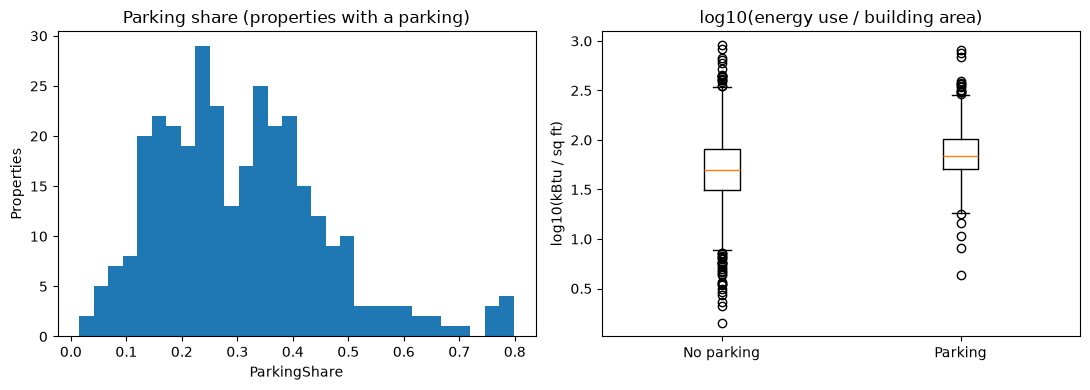

,Spearman with log intensity
HasParking (all properties),0.22
ParkingShare (all properties),0.23
ParkingShare (properties with a parking),0.26


In [3]:
target = df["SiteEnergyUse(kBtu)"]
log_intensity = np.log10(target / b)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df.loc[has_parking, "ParkingShare"], bins=30)
axes[0].set(
    title="Parking share (properties with a parking)",
    xlabel="ParkingShare",
    ylabel="Properties",
)
axes[1].boxplot(
    [log_intensity[~has_parking], log_intensity[has_parking]],
    tick_labels=["No parking", "Parking"],
)
axes[1].set(title="log10(energy use / building area)", ylabel="log10(kBtu / sq ft)")
plt.tight_layout()
plt.show()

correlations = {
    "HasParking (all properties)": spearmanr(has_parking, log_intensity).statistic,
    "ParkingShare (all properties)": spearmanr(
        df["ParkingShare"], log_intensity
    ).statistic,
    "ParkingShare (properties with a parking)": spearmanr(
        df.loc[has_parking, "ParkingShare"], log_intensity[has_parking]
    ).statistic,
}
pd.Series(correlations, name="Spearman with log intensity").round(2).to_frame()

### Decisions

The correlations are positive. For the same building area, properties with a parking use more energy.

On all properties, the flag and the share are equivalent (0.22 vs 0.23). Among properties with a parking, the share still correlates with intensity (0.26): the size of the parking matters, not only its presence. `ParkingShare` alone is kept, no `HasParking` flag.

Together with the building area, `ParkingShare` carries the same information in the form that matches the hypothesis (a proportion), without adding another variable correlated with size. `PropertyGFAParking` is dropped.

In [4]:
columns_to_drop.append("PropertyGFAParking")

## 2. Mixed usage

A property hosting several activities (e.g. offices and a restaurant) has a different energy profile from a single-use property of the same type.

First, look at what `SecondLargestPropertyUseType` contains, and in particular how much of it is "Parking" (already captured by `ParkingShare`).

Properties with a second use type: 831 / 1535 (54.1%)
Share of 'Parking' among second use types: 39.5%


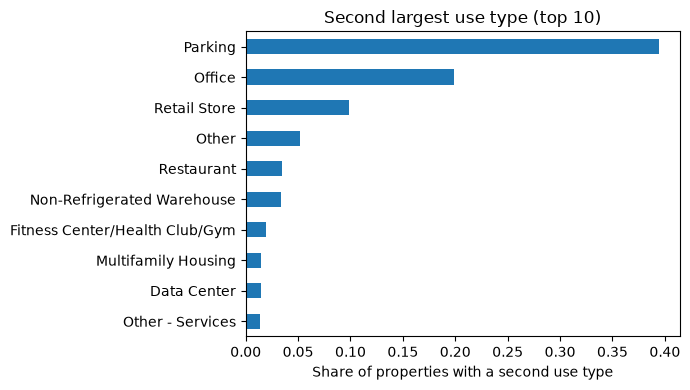

,count,share
SecondLargestPropertyUseType,,
Parking,328,0.395
Office,165,0.199
Retail Store,82,0.099
Other,43,0.052
Restaurant,29,0.035
Non-Refrigerated Warehouse,28,0.034
Fitness Center/Health Club/Gym,16,0.019
Data Center,12,0.014
Multifamily Housing,12,0.014


In [5]:
second = df["SecondLargestPropertyUseType"]
n_second = second.notna().sum()
print(
    f"Properties with a second use type: {n_second} / {len(df)} ({n_second / len(df):.1%})"
)

breakdown = second.value_counts().to_frame("count")
breakdown["share"] = breakdown["count"] / n_second
print(
    f"Share of 'Parking' among second use types: {breakdown.loc['Parking', 'share']:.1%}"
)

top = breakdown.head(10)
ax = top["share"].sort_values().plot.barh(figsize=(7, 4))
ax.set(
    title="Second largest use type (top 10)",
    xlabel="Share of properties with a second use type",
    ylabel="",
)
plt.tight_layout()
plt.show()

top.round(3)

Parking is the most frequent second use (40%). A flag based on "has a second use type" would mostly duplicate the parking information. Moreover, the two sources about parking do not agree: 328 properties declare Parking as second use, 325 have a parking area, and only 201 have both. `PropertyGFAParking` (through `ParkingShare`) is used as the reference for parking, and **Parking is excluded from the mixed-usage definition**.

### All declared use types

`ListOfAllPropertyUseTypes` lists all the use types of a property, including minor ones hidden by the two largest.

In [6]:
combinations = df["ListOfAllPropertyUseTypes"].value_counts()
print(
    f"Distinct combinations: {len(combinations)} (appearing once: {(combinations == 1).sum()})"
)
combinations.head(20).to_frame("count")

Distinct combinations: 360 (appearing once: 245)


,count
ListOfAllPropertyUseTypes,
Office,132
"Office, Parking",119
Non-Refrigerated Warehouse,100
"Non-Refrigerated Warehouse, Office",61
Other,58
Retail Store,52
K-12 School,46
Worship Facility,46
Hotel,43


### Split the list into use types

Some labels contain commas, e.g. `Repair Services (Vehicle, Shoe, Locksmith, etc)`, so the list is split on commas that are not inside parentheses.

In [7]:
all_uses = df["ListOfAllPropertyUseTypes"]
assert all_uses.notna().all(), "NaN would be counted as a use type after explode"

# Split on commas that are not inside parentheses
use_types = all_uses.str.split(r",\s*(?![^()]*\))", regex=True).explode()

# Check: labels that never appear as largest or second largest use
reference = set(df["LargestPropertyUseType"].dropna()) | set(second.dropna())
use_types[~use_types.isin(reference)].value_counts().to_frame("properties")

,properties
ListOfAllPropertyUseTypes,
Other - Technology/Science,6
Fast Food Restaurant,2
Outpatient Rehabilitation/Physical Therapy,2
Energy/Power Station,1
Single Family Home,1
Vocat,1


Only 6 labels never appear as largest or second largest use. Five are valid Portfolio Manager use types, minor in every property that declares them. `Vocat` is a truncated `Vocational School`: one list is cut at 255 characters. This does not affect the mixed-usage flag (that property declares 11 uses). The split is therefore correct.

In [8]:
# Number of distinct use types, parking excluded
n_uses = (
    use_types[use_types != "Parking"]
    .groupby(level=0)
    .nunique()
    .reindex(df.index, fill_value=0)  # properties declaring only Parking
)
print(
    f"Properties with more than one use (parking excluded): "
    f"{(n_uses > 1).sum()} / {len(df)} ({(n_uses > 1).mean():.1%})"
)
n_uses.value_counts().sort_index().to_frame("properties")

Properties with more than one use (parking excluded): 592 / 1535 (38.6%)


,properties
ListOfAllPropertyUseTypes,
1,943
2,351
3,149
4,56
5,22
6,8
7,1
8,2
9,2


### Definition of `HasMixedUsage`

Two possible definitions:

- **Variant A:** `SecondLargestPropertyUseType` is specified and is not "Parking" (considers only the two largest uses).
- **Variant B:** at least two distinct uses other than "Parking" in `ListOfAllPropertyUseTypes` (considers all declared uses).

In [9]:
variant_a = second.notna() & (second != "Parking")
variant_b = n_uses >= 2

print(
    f"Variant A: {variant_a.sum()} ({variant_a.mean():.1%}) | Variant B: {variant_b.sum()} ({variant_b.mean():.1%})"
)
pd.crosstab(variant_a.rename("Variant A"), variant_b.rename("Variant B"), margins=True)

Variant A: 503 (32.8%) | Variant B: 592 (38.6%)


Variant B,False,True,All
Variant A,,,
False,931,101,1032
True,12,491,503
All,943,592,1535


The variants disagree on 113 properties.

**A False, B True (101):** Parking is the second largest use, so A misses the real second activity ranked third (e.g. `Hotel, Parking, Restaurant`).

**A True, B False (12):** listed below.

In [10]:
use_columns = [
    "LargestPropertyUseType",
    "SecondLargestPropertyUseType",
    "ListOfAllPropertyUseTypes",
]
df.loc[variant_a & ~variant_b, use_columns]

,LargestPropertyUseType,SecondLargestPropertyUseType,ListOfAllPropertyUseTypes
47,Hotel,Restaurant,Hotel
326,Parking,Retail Store,"Parking, Retail Store"
368,Parking,Medical Office,"Medical Office, Parking"
449,Parking,Office,"Office, Parking"
468,Other,Retail Store,Retail Store
857,Parking,K-12 School,"K-12 School, Parking"
1121,Parking,Retail Store,"Parking, Retail Store"
1180,Parking,Office,"Office, Parking"
1443,Parking,Other - Entertainment/Public Assembly,"Other - Entertainment/Public Assembly, Parking"
1448,Office,Office,Office


- 9 properties have Parking as largest use and a single other activity (e.g. a parking garage with retail on the ground floor). B considers them single-use once the parking is set aside, which is consistent with the parking being handled by `ParkingShare`.
- 3 properties have inconsistent declarations: a second use absent from the list (`Hotel` + `Restaurant`, `Other` + `Retail Store`) or identical to the first one (`Office` + `Office`).

### Decision

**Variant B is kept:** it does not depend on the rank of Parking and uses all the declared uses. With 592 mixed vs 943 single-use properties, both groups are large enough for the flag to be learned.

In [11]:
columns_to_drop.extend(use_columns)
df["HasMixedUsage"] = variant_b.astype(int)
df["HasMixedUsage"].value_counts().to_frame("properties")

,properties
HasMixedUsage,
0,943
1,592


## 3. Construction period

The year of construction is grouped into periods defined by fixed, business-justified bounds: the successive Washington State energy codes. A building is designed under the code in force when it was built, so the period carries information about its envelope and systems that the raw year does not make explicit.

* 1977: First State Energy Code
* 1991: Nonresidential Energy Code Act
* 2009: The Washington State Energy Code is revised and reformatted to align with the IECC

*Source [Washington State Building Code Council History](https://sbcc.wa.gov/about-sbcc/history)*

In [12]:
period_labels = ["Before 1977", "1977-1990", "1991-2008", "2009+"]

period = pd.cut(
    df["YearBuilt"],
    bins=[-np.inf, 1976, 1990, 2008, np.inf],
    labels=period_labels,
).rename("ConstructionPeriod")

by_period = (
    period.value_counts()
    .sort_index()
    .rename_axis("ConstructionPeriod")
    .to_frame("properties")
)
by_period["share"] = (by_period["properties"] / len(df)).round(3)
by_period

,properties,share
ConstructionPeriod,,
Before 1977,953,0.621
1977-1990,233,0.152
1991-2008,271,0.177
2009+,78,0.051


### Splitting the first period at 1946

"Before 1977" holds about two thirds of the properties. It is split at the end of the Second World War (< 1946 vs 1946-1976) to check whether the two halves differ in energy intensity.

In [13]:
period_labels = ["Before 1946", "1946-1976", "1977-1990", "1991-2008", "2009+"]
period = pd.cut(
    df["YearBuilt"],
    bins=[-np.inf, 1945, 1976, 1990, 2008, np.inf],
    labels=period_labels,
).rename("ConstructionPeriod")

intensity = df["SiteEnergyUse(kBtu)"] / df["PropertyGFABuilding(s)"]
(intensity.groupby(period).agg(properties="count", median_intensity="median").round(1))

,properties,median_intensity
ConstructionPeriod,,
Before 1946,453,46.2
1946-1976,500,52.5
1977-1990,233,55.1
1991-2008,271,72.9
2009+,78,45.9


### Decision

The 1946 split is kept: both halves are large (453 and 500 properties), giving five periods. The two halves also correspond to different building practices. Before 1946: thick masonry (high thermal inertia), windows that open, little or no air conditioning. 1946-1976: glazed curtain walls, airtight buildings, widespread use of air conditioning and mechanical ventilation, cheap energy. The median intensity is about 13% higher after 1946 than before.

The median intensity rises with the construction period up to 1991-2008, then falls for 2009+. The relationship is not monotonic, so the periods replace `YearBuilt`: a linear model on the year would only capture a slope.

Two caveats on the interpretation:

- Older buildings are more likely to have been retrofitted, which `YearBuilt` does not capture. The period describes the original construction, not the current state.
- The drop for 2009+ is consistent with the alignment with the IECC, but with only 78 properties and no control for their uses, it is only consistent with it, not proof.

In [14]:
df["ConstructionPeriod"] = period
columns_to_drop.append("YearBuilt")

## 4. Floor area per floor

For the same floor area, a low, wide building (such as a warehouse or shopping center) does not behave like a tower. But the expected effect works both ways: large open spaces mean less facade per square meter, and therefore less heat loss, but they also mean central areas far from windows, which require more lighting and mechanical ventilation.

In [15]:
floors = df["NumberofFloors"]

print(f"dtype: {floors.dtype}")
print(f"Missing (NaN): {floors.isna().sum()}")
print(f"Zero floors:   {(floors == 0).sum()}")
print(f"Negative:      {(floors < 0).sum()}")
print(f"Non-integer:   {(floors.dropna() % 1 != 0).sum()}")

# Check: dividing by 0 would give inf without any error
assert not np.isinf(b / floors).any(), "Floors equal to 0 produce inf"

dtype: float64
Missing (NaN): 15
Zero floors:   0
Negative:      0
Non-integer:   0


**Zero floors:** none. The column is `float64` because of 15 missing values (NaN), which the cleaning already produced: there is no 0 left, so no `inf` can appear. The assertion above guards against it if the cleaning changes. Dividing by a NaN gives NaN, which is the expected behaviour for these 15 properties.

### Campuses: `NumberofBuildings > 1`

In [16]:
is_campus = df["NumberofBuildings"] > 1
print(
    f"Properties with NumberofBuildings > 1: {is_campus.sum()} / {len(df)} ({is_campus.mean():.1%})"
)
print(f"Of which with a missing floor count: {(is_campus & floors.isna()).sum()}")

print("\nNumber of floors and area per 'floor':")
pd.DataFrame(
    {
        "NumberofFloors (campus)": floors[is_campus].describe(),
        "NumberofFloors (single)": floors[~is_campus].describe(),
        "Area per floor (campus)": (b / floors)[is_campus].describe(),
        "Area per floor (single)": (b / floors)[~is_campus].describe(),
    }
).round(0)

Properties with NumberofBuildings > 1: 51 / 1535 (3.3%)
Of which with a missing floor count: 2

Number of floors and area per 'floor':


,NumberofFloors (campus),NumberofFloors (single),Area per floor (campus),Area per floor (single)
count,49.0,1471.0,49.0,1471.0
mean,3.0,4.0,82087.0,28730.0
std,3.0,6.0,93322.0,35047.0
min,1.0,1.0,5589.0,3231.0
25%,1.0,1.0,23166.0,11890.0
50%,2.0,2.0,55722.0,20218.0
75%,3.0,4.0,87900.0,31221.0
max,14.0,76.0,415632.0,530039.0


51 properties (3.3%) have `NumberofBuildings > 1`. For them, `NumberofFloors` is a single number for several buildings: it is not documented whether it is the maximum, the average or the floor count of the main building. The result is hard to interpret: the total area of up to 27 buildings is divided by 1 or 2 floors, so the "area per floor" of campuses is much larger and more spread out than for single buildings (median about 56,000 vs 20,000 sq ft, up to 415,000). It is not the floor plate of any real building.

**These rows are set to NaN** for `FloorAreaPerFloor`. The feature is only meaningful when one building has one floor count. Together with the 15 properties with a missing floor count (2 of them are also campuses), 64 properties have no value, and this will have to be handled at the modelling stage (imputation inside the cross-validation).

### Extreme values

In [17]:
area_per_floor = b / floors
columns = [
    "PrimaryPropertyType",
    "NumberofBuildings",
    "NumberofFloors",
    "PropertyGFABuilding(s)",
]
extremes = (
    df[columns]
    .assign(AreaPerFloor=area_per_floor.round(0))
    .dropna(subset=["AreaPerFloor"])
)

print(f"Floors:         min {floors.min():.0f}, max {floors.max():.0f}")
print(
    f"Area per floor: min {area_per_floor.min():,.0f}, max {area_per_floor.max():,.0f}"
)
print(f"Median {area_per_floor.median():,.0f} sq ft per floor")

print("\nLowest area per floor (many floors for little area):")
display(extremes.nsmallest(5, "AreaPerFloor"))
print("Highest area per floor (few floors for a large area):")
display(extremes.nlargest(5, "AreaPerFloor"))
print("Most floors:")
display(extremes.nlargest(5, "NumberofFloors"))

Floors:         min 1, max 76
Area per floor: min 3,231, max 530,039
Median 20,506 sq ft per floor

Lowest area per floor (many floors for little area):


,PrimaryPropertyType,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),AreaPerFloor
1431,Restaurant,1.0,13.0,42000,3231.0
676,Hotel,1.0,11.0,36240,3295.0
614,Small- and Mid-Sized Office,1.0,7.0,23622,3375.0
42,Hotel,1.0,20.0,88591,4430.0
834,Mixed Use Property,1.0,4.0,17824,4456.0


Highest area per floor (few floors for a large area):


,PrimaryPropertyType,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),AreaPerFloor
100,Retail Store,1.0,1.0,530039,530039.0
971,Hospital,8.0,1.0,415632,415632.0
541,Distribution Center,1.0,1.0,411584,411584.0
124,Other,1.0,3.0,1172127,390709.0
62,Other,1.0,1.0,389000,389000.0


Most floors:


,PrimaryPropertyType,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),AreaPerFloor
498,Large Office,1.0,76.0,1632820,21484.0
182,Large Office,1.0,63.0,1195387,18974.0
240,Large Office,1.0,56.0,1215718,21709.0
220,Large Office,1.0,55.0,1115000,20273.0
178,Large Office,1.0,49.0,754455,15397.0


Nothing is removed at this stage.

- **Tall end:** the 76, 63, 56 and 55-storey buildings are all Large Offices of 1.1 to 1.6 million sq ft, i.e. about 19,000 to 22,000 sq ft per floor. These are consistent towers.
- **Low end:** the smallest floor areas (3,200 to 4,500 sq ft per floor) come from buildings with many floors for their size, e.g. 13 floors for 42,000 sq ft (a restaurant) or 11 floors for 36,000 sq ft (a hotel). They are unusual, perhaps a floor count that includes basements or mezzanines, but not impossible.
- **Wide end:** the 1-storey properties of 390,000 to 530,000 sq ft are distribution centers, a retail store and an "Other" use: plausible. The 8-building hospital in the table is a campus, set to NaN below. One row stands out: an "Other" with 3 floors and 1.17 million sq ft (390,000 sq ft per floor) is Safeco Field, a baseball stadium. It's not a campus and it is plausible.

The distribution is strongly right-skewed (median about 20,000 sq ft, maximum 530,039). The skew will be handled by a log transform at the modelling stage, not by deletion.

In [18]:
is_campus = df["NumberofBuildings"] > 1

# Floor area per floor: NaN when the floor count is missing or ambiguous (campus)
df["FloorAreaPerFloor"] = (b / floors).where(~is_campus)

print(f"Rows with a value: {df['FloorAreaPerFloor'].notna().sum()} / {len(df)}")
print(f"Rows set to NaN:   {df['FloorAreaPerFloor'].isna().sum()}")
df["FloorAreaPerFloor"].describe().round(0).to_frame()

Rows with a value: 1471 / 1535
Rows set to NaN:   64


,FloorAreaPerFloor
count,1471.0
mean,28730.0
std,35047.0
min,3231.0
25%,11890.0
50%,20218.0
75%,31221.0
max,530039.0


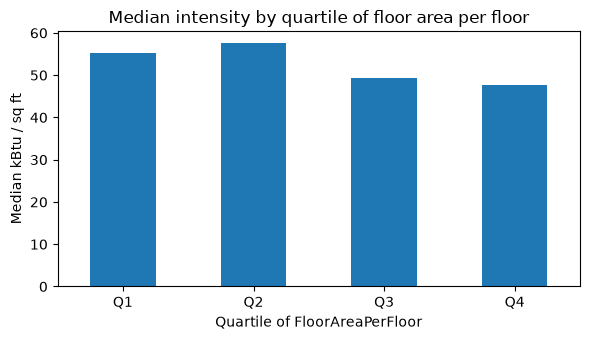

Spearman with log intensity: -0.07


,properties,median_intensity,area_per_floor_range
FloorAreaPerFloor,,,
Q1,368,55.2,"3,231 - 11,868"
Q2,368,57.5,"11,912 - 20,218"
Q3,367,49.3,"20,233 - 31,110"
Q4,368,47.7,"31,332 - 530,039"


In [19]:
known = df["FloorAreaPerFloor"].notna()
quartile = pd.qcut(df["FloorAreaPerFloor"], 4, labels=["Q1", "Q2", "Q3", "Q4"])

by_quartile = (
    intensity.groupby(quartile)
    .agg(properties="count", median_intensity="median")
    .round(1)
)
by_quartile["area_per_floor_range"] = (
    df["FloorAreaPerFloor"]
    .groupby(quartile)
    .agg(lambda s: f"{s.min():,.0f} - {s.max():,.0f}")
)

ax = by_quartile["median_intensity"].plot.bar(rot=0, figsize=(6, 3.5))
ax.set(
    title="Median intensity by quartile of floor area per floor",
    xlabel="Quartile of FloorAreaPerFloor",
    ylabel="Median kBtu / sq ft",
)
plt.tight_layout()
plt.show()

print(
    "Spearman with log intensity: "
    f"{spearmanr(df.loc[known, 'FloorAreaPerFloor'], log_intensity[known]).statistic:.2f}"
)
by_quartile

### Decision

The relationship is weak: intensity is roughly flat for the two narrowest quartiles, then about 15% lower for the widest ones (Spearman −0.07). This is compatible with the two opposite effects described above, but the differences are small compared to the spread within each quartile.

Two caveats:

- The drop at the wide end is partly a use effect: warehouses are frequent among the widest floors and small offices among the narrowest. The feature may partly act as a proxy for the use type.
- The differences between quartiles are modest, so the shape is indicative only.

`FloorAreaPerFloor` is kept. The shape is not a straight line, so a linear model would only capture the weak overall slope, while tree-based models can use the bend. To revisit at the modelling stage (permutation importance, with and without the feature).

## 5. Conclusion

State of every column of the dataset at the end of this notebook. **Kept**: already there and used as is. **New**: engineered in this notebook. **Removed**: not passed to the modelling.

| Column | Type | Status | Notes |
|---|---|---|---|
| `SiteEnergyUse(kBtu)` | float64 | Kept | Target. Right-skewed: modeled as log10 (decision of notebook 1), with predictions transformed back to kBtu to compute the metrics. |
| `PropertyGFABuilding(s)` | int64 | Kept | Size variable, parking excluded. Right-skewed: log transform expected. |
| `PrimaryPropertyType` | str | Kept | Categorical, needs encoding (one-hot). Carries the main use of the property (decision of notebook 1). |
| `Neighborhood` | str | Kept | Categorical, needs encoding (one-hot). |
| `Latitude` | float64 | Kept | Location. Numeric, no encoding. |
| `Longitude` | float64 | Kept | Location. Numeric, no encoding. |
| `NumberofFloors` | float64 | Kept | Missing for a few properties, to be imputed inside the cross-validation. Its redundancy with `FloorAreaPerFloor` is to be checked. |
| `NumberofBuildings` | float64 | Kept | Campus vs single building. Its redundancy with the other size variables is to be checked. |
| `ParkingShare` | float64 | New | Parking area as a share of the total area. 0 when there is no parking (a real value, not a missing one). |
| `HasMixedUsage` | int64 | New | Binary flag (0/1): at least two distinct uses other than parking. No encoding needed. |
| `ConstructionPeriod` | category | New | Five periods based on the energy codes. Categorical, needs encoding (one-hot): the effect is not monotonic. |
| `FloorAreaPerFloor` | float64 | New | Building area divided by the number of floors. Missing for campuses and for properties without a floor count: to be imputed inside the cross-validation. Right-skewed: log transform expected. |
| `PropertyGFAParking` | int64 | Removed | Replaced by `ParkingShare`, which carries the same information as a proportion of the total area. |
| `YearBuilt` | int64 | Removed | Summarized by `ConstructionPeriod`, in a form that matches the business reference points (energy codes). |
| `LargestPropertyUseType` | str | Removed | Never used as a feature. The use is carried by `PrimaryPropertyType` (decision of notebook 1), and it has too many categories for a one-hot encoding. |
| `SecondLargestPropertyUseType` | str | Removed | Only used to compare the two flag variants. What it adds is found in `HasMixedUsage`. |
| `ListOfAllPropertyUseTypes` | str | Removed | Many combinations, most of them unique. Only useful to count the distinct uses, which is done in `HasMixedUsage`. |

Points to check at the modelling stage: the importance of the weakest signals (`FloorAreaPerFloor`, `ParkingShare`) with and without the feature, and for the linear model, do not log-transform the building area, the floor count and `FloorAreaPerFloor` together.

The comparisons with the target in this notebook (correlations, medians by group) were computed on the full dataset, before the train/test split. They are descriptive: they justify creating the features, not keeping them. The features are re-evaluated on the training set only, through cross-validation and permutation importance, in `03_modeling.ipynb`.



In [20]:
print(f"Columns to drop: {columns_to_drop}")
df.drop(columns=columns_to_drop, inplace=True)

Columns to drop: ['PropertyGFAParking', 'LargestPropertyUseType', 'SecondLargestPropertyUseType', 'ListOfAllPropertyUseTypes', 'YearBuilt']


## 6. Save the dataset with the new features

The dataset with the four new features is saved in parquet format, which keeps the column types, to be loaded by the next notebook (`03_modeling.ipynb`).

In [21]:
from pathlib import Path

PROCESSED_PATH = Path("../data/processed/buildings_feature_engineered.parquet")
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_parquet(PROCESSED_PATH)
print(f"Saved {df.shape[0]} rows x {df.shape[1]} columns to {PROCESSED_PATH}")

Saved 1535 rows x 12 columns to ../data/processed/buildings_feature_engineered.parquet
